## 0. Setup & configuration

In [1]:
import os, time, glob, pickle, shutil, zipfile
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

print("OpenCV version:", cv2.__version__)

OpenCV version: 4.14.0


In [2]:

DB_DIR   = "landmarks_db"
TEST_DIR = "test_queries"
OUT_DIR  = "outputs"
for d in (DB_DIR, TEST_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)

LANDMARKS = {
    "Eiffel Tower":        "Eiffel Tower Paris",
    "Taj Mahal":           "Taj Mahal Agra",
    "Great Wall of China": "Great Wall of China",
    "Statue of Liberty":   "Statue of Liberty New York",
    "Colosseum":           "Colosseum Rome",
}
UNKNOWN_SEARCH = ["Pyramids of Giza", "Sydney Opera House"]
N_REFS, N_TESTS = 6, 2

MAX_DIM          = 1000
N_FEATURES       = 3000
RATIO            = 0.75
RANSAC_THRESH    = 5.0

MIN_GOOD         = 20
MIN_H_MATCHES    = 15
MIN_INLIERS      = 15
MIN_INLIER_RATIO = 0.25
MARGIN           = 1.5

sift = cv2.SIFT_create(nfeatures=N_FEATURES)
bf   = cv2.BFMatcher(cv2.NORM_L2)

EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
def find_images(folder):
    return sorted(p for p in glob.glob(os.path.join(folder, "*")) if p.lower().endswith(EXTS))
def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

### Option A – automatic download (Wikimedia Commons)

In [3]:
HEADERS = {"User-Agent": "LandmarkSIFTLab/1.0 (university lab assignment; python-requests)"}
API = "https://commons.wikimedia.org/w/api.php"

def commons_image_urls(query, limit=40, width=1024):
    params = dict(action="query", format="json", generator="search",
                  gsrsearch=f"{query} filetype:bitmap", gsrnamespace=6, gsrlimit=limit,
                  prop="imageinfo", iiprop="url|mime|size", iiurlwidth=width)
    r = requests.get(API, params=params, headers=HEADERS, timeout=30)
    r.raise_for_status()
    pages = r.json().get("query", {}).get("pages", {})
    urls = []
    for p in sorted(pages.values(), key=lambda p: p.get("index", 0)):
        ii = p.get("imageinfo", [{}])[0]
        if ii.get("mime") == "image/jpeg" and ii.get("width", 0) >= 800:
            urls.append(ii.get("thumburl") or ii.get("url"))
    return urls

def download_image(url, dest, retries=4):
    for k in range(retries):
        try:
            r = requests.get(url, headers=HEADERS, timeout=60)
            if r.status_code == 429:
                time.sleep(3 * (k + 1)); continue
            r.raise_for_status()
            if cv2.imdecode(np.frombuffer(r.content, np.uint8), cv2.IMREAD_COLOR) is None:
                return False
            with open(dest, "wb") as f:
                f.write(r.content)
            return True
        except Exception as e:
            time.sleep(2)
    return False

def fetch_set(search, n_ref, n_test, ref_dir, test_dir):
    urls = commons_image_urls(search)
    os.makedirs(ref_dir, exist_ok=True)
    if test_dir: os.makedirs(test_dir, exist_ok=True)
    got_ref = got_test = 0
    for u in urls:
        if got_ref < n_ref:
            if download_image(u, os.path.join(ref_dir, f"ref_{got_ref+1:02d}.jpg")): got_ref += 1
        elif test_dir and got_test < n_test:
            if download_image(u, os.path.join(test_dir, f"test_{got_test+1:02d}.jpg")): got_test += 1
        else:
            break
        time.sleep(1.0)
    return got_ref, got_test

for label, search in LANDMARKS.items():
    ref_dir, test_dir = os.path.join(DB_DIR, label), os.path.join(TEST_DIR, label)
    if len(find_images(ref_dir)) >= N_REFS:
        print(f"{label}: already present, skipping"); continue
    r, t = fetch_set(search, N_REFS, N_TESTS, ref_dir, test_dir)
    print(f"{label}: {r} reference + {t} test images")

for search in UNKNOWN_SEARCH[:1]:
    d = os.path.join(TEST_DIR, "_unknown")
    if len(find_images(d)) >= 2: continue
    _, t = fetch_set(search, 0, 2, os.path.join(TEST_DIR, "_tmp"), d)
    print(f"Unknown ({search}): {t} test images")
shutil.rmtree(os.path.join(TEST_DIR, "_tmp"), ignore_errors=True)

Eiffel Tower: 6 reference + 2 test images
Taj Mahal: 6 reference + 2 test images
Great Wall of China: 6 reference + 2 test images
Statue of Liberty: 6 reference + 2 test images
Colosseum: 6 reference + 2 test images
Unknown (Pyramids of Giza): 2 test images


### Option B – upload your own ZIP (skip Option A if you use this)

In [4]:

from google.colab import files
up = files.upload()
for name in up:
    if name.lower().endswith(".zip"):
        with zipfile.ZipFile(name) as z:
            z.extractall(".")
        print("Extracted", name)
print({d: len(find_images(os.path.join(DB_DIR, d))) for d in sorted(os.listdir(DB_DIR))})

Saving eiffle tower.html to eiffle tower.html
{'Colosseum': 6, 'Eiffel Tower': 6, 'Great Wall of China': 6, 'Statue of Liberty': 6, 'Taj Mahal': 6}


### Database overview

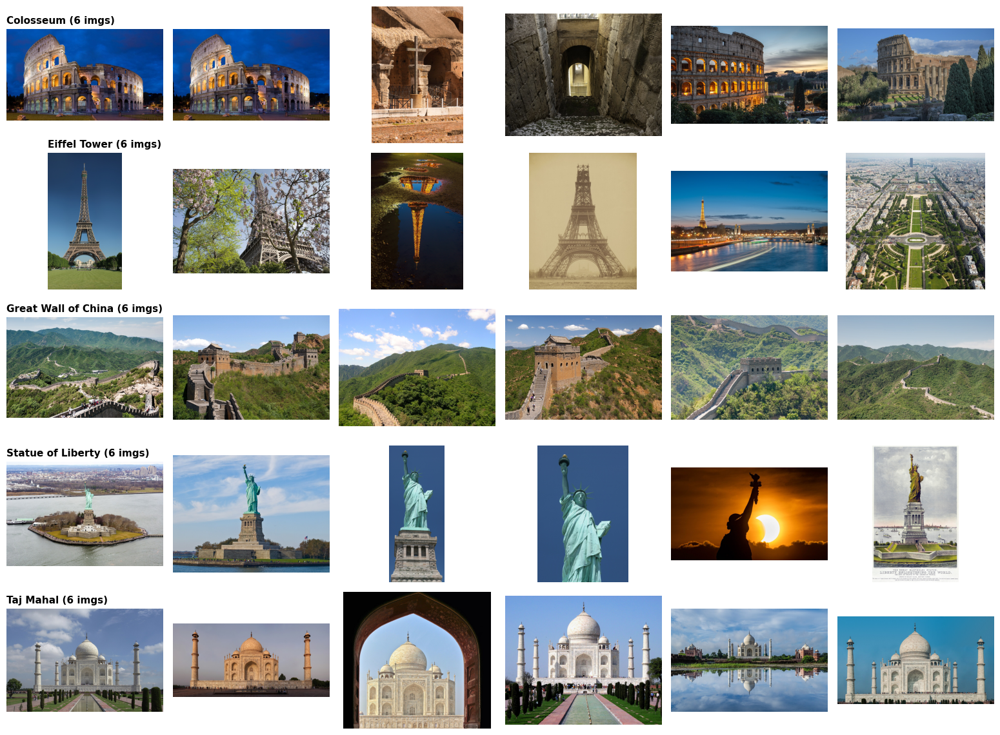

In [5]:
def show_database(max_per=6):
    labels = sorted(d for d in os.listdir(DB_DIR) if os.path.isdir(os.path.join(DB_DIR, d)))
    fig, axes = plt.subplots(len(labels), max_per, figsize=(2.6 * max_per, 2.3 * len(labels)))
    axes = np.atleast_2d(axes)
    for r, lab in enumerate(labels):
        paths = find_images(os.path.join(DB_DIR, lab))
        for c in range(max_per):
            ax = axes[r, c]; ax.axis("off")
            if c < len(paths):
                ax.imshow(rgb(cv2.imread(paths[c])))
            if c == 0:
                ax.set_title(f"{lab} ({len(paths)} imgs)", loc="left", fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "task1_database.png"), dpi=120)
    plt.show()
    assert len(labels) >= 5, "Need at least 5 landmarks in the database"

show_database()

In [6]:
def load_image(src, max_dim=MAX_DIM):
    img = cv2.imread(src) if isinstance(src, str) else src.copy()
    if img is None:
        raise FileNotFoundError(f"Cannot read image: {src}")
    h, w = img.shape[:2]
    s = max_dim / max(h, w)
    if s < 1:
        img = cv2.resize(img, (int(w * s), int(h * s)), interpolation=cv2.INTER_AREA)
    return img

def extract_sift(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)          # 1. grayscale
    kp, des = sift.detectAndCompute(gray, None)           # 2-3. keypoints + descriptors
    return gray, kp, des

database = []     # one entry per reference image
for lab in sorted(d for d in os.listdir(DB_DIR) if os.path.isdir(os.path.join(DB_DIR, d))):
    for p in find_images(os.path.join(DB_DIR, lab)):
        img = load_image(p)
        gray, kp, des = extract_sift(img)
        if des is None or len(kp) < 10:
            print("Skipping (too few features):", p); continue
        database.append(dict(label=lab, path=p, img=img, gray=gray, kp=kp, des=des))

summary = (pd.DataFrame([{"Landmark": d["label"], "Keypoints": len(d["kp"])} for d in database])
             .groupby("Landmark").agg(Images=("Keypoints", "count"), Avg_keypoints=("Keypoints", "mean")).round(0))
print(f"{len(database)} reference images processed")
summary

30 reference images processed


,Images,Avg_keypoints
Landmark,,
Colosseum,6,2999.0
Eiffel Tower,6,2481.0
Great Wall of China,6,3000.0
Statue of Liberty,6,1811.0
Taj Mahal,6,2550.0


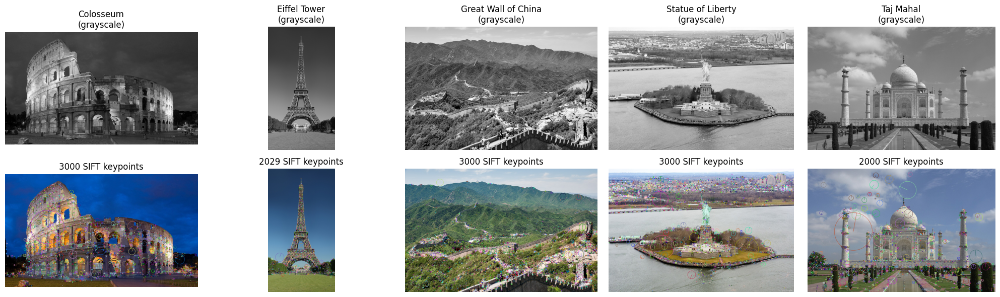

Descriptor array shape of one image: (3000, 128) (keypoints x 128)


In [7]:

labels = sorted({d["label"] for d in database})
fig, axes = plt.subplots(2, len(labels), figsize=(4 * len(labels), 6))
for i, lab in enumerate(labels):
    d = next(x for x in database if x["label"] == lab)
    vis = cv2.drawKeypoints(d["img"], d["kp"], None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    axes[0, i].imshow(cv2.cvtColor(d["gray"], cv2.COLOR_GRAY2RGB)); axes[0, i].set_title(f"{lab}\n(grayscale)"); axes[0, i].axis("off")
    axes[1, i].imshow(rgb(vis)); axes[1, i].set_title(f"{len(d['kp'])} SIFT keypoints"); axes[1, i].axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "task2_reference_keypoints.png"), dpi=120)
plt.show()
print("Descriptor array shape of one image:", database[0]["des"].shape, "(keypoints x 128)")

In [8]:
# 5. Store descriptors with their landmark labels (keypoints are converted to plain tuples so they can be pickled)
def kp_to_tuple(k):  return (k.pt, k.size, k.angle, k.response, k.octave, k.class_id)
def tuple_to_kp(t):  return cv2.KeyPoint(x=t[0][0], y=t[0][1], size=t[1], angle=t[2], response=t[3], octave=t[4], class_id=t[5])

DB_FILE = os.path.join(OUT_DIR, "sift_database.pkl")
with open(DB_FILE, "wb") as f:
    pickle.dump([dict(label=d["label"], path=d["path"], kp=[kp_to_tuple(k) for k in d["kp"]], des=d["des"]) for d in database], f)
print(f"Saved {len(database)} descriptor sets -> {DB_FILE}  ({os.path.getsize(DB_FILE)/1e6:.1f} MB)")

Saved 30 descriptor sets -> outputs/sift_database.pkl  (44.1 MB)


In [13]:
def process_query(src):
    img = load_image(src)
    gray, kp, des = extract_sift(img)
    return dict(img=img, gray=gray, kp=kp, des=des)

def show_query(q, title="Query image"):
    vis = cv2.drawKeypoints(q["img"], q["kp"], None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ax[0].imshow(rgb(q["img"])); ax[0].set_title(title); ax[0].axis("off")
    ax[1].imshow(rgb(vis));      ax[1].set_title(f"Detected SIFT keypoints: {len(q['kp'])}"); ax[1].axis("off")
    plt.tight_layout(); plt.show()

In [14]:
def ratio_matches(des_q, des_r, ratio=RATIO):
    # KNN (k=2) + Lowe's ratio test. queryIdx -> query keypoint, trainIdx -> reference keypoint.
    if des_q is None or des_r is None or len(des_q) < 2 or len(des_r) < 2:
        return []
    knn = bf.knnMatch(des_q, des_r, k=2)
    return [p[0] for p in knn if len(p) == 2 and p[0].distance < ratio * p[1].distance]

def verify_geometry(q, ref, good):

    res = dict(H=None, mask=None, inliers=0, corners=None, valid=False, reason="")
    if len(good) < MIN_H_MATCHES:
        res["reason"] = f"too few reliable matches for homography ({len(good)} < {MIN_H_MATCHES})"; return res
    src = np.float32([ref["kp"][m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([q["kp"][m.queryIdx].pt  for m in good]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, RANSAC_THRESH)
    if H is None or mask is None:
        res["reason"] = "RANSAC could not estimate a homography"; return res
    res.update(H=H, mask=mask, inliers=int(mask.sum()))
    h, w = ref["img"].shape[:2]
    corners = cv2.perspectiveTransform(np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2), H)
    res["corners"] = corners
    qh, qw = q["img"].shape[:2]
    area = cv2.contourArea(corners)
    poly = corners.reshape(-1, 2)
    if not cv2.isContourConvex(np.int32(corners)):
        res["reason"] = "projected polygon is not convex"
    elif not (0.01 * qh * qw <= area <= 20 * qh * qw):
        res["reason"] = "projected polygon has implausible size"
    elif np.abs(poly).max() > 10 * max(qh, qw):
        res["reason"] = "projected polygon is far outside the image"
    elif res["inliers"] < MIN_INLIERS:
        res["reason"] = f"too few RANSAC inliers ({res['inliers']} < {MIN_INLIERS})"
    else:
        res["valid"] = True
    return res

def recognize(q):

    per_ref = []
    for ref in database:
        good = ratio_matches(q["des"], ref["des"])
        geo = verify_geometry(q, ref, good)
        per_ref.append(dict(ref=ref, good=good, **geo))

    per_lm = {}
    for r in per_ref:
        lab = r["ref"]["label"]
        r_key = (r["inliers"] if r["valid"] else 0, len(r["good"]))
        entry = per_lm.setdefault(lab, dict(label=lab, total_good=0, best=None, key=(-1, -1)))
        entry["total_good"] += len(r["good"])
        if r_key > entry["key"]:
            entry["key"], entry["best"] = r_key, r

    ranked = sorted(per_lm.values(), key=lambda e: e["key"], reverse=True)
    top = ranked[0]; best = top["best"]
    runner_up_inl = ranked[1]["key"][0] if len(ranked) > 1 else 0
    n_good, n_inl = len(best["good"]), best["inliers"]
    ratio_inl = n_inl / max(n_good, 1)

    reasons = []
    if n_good < MIN_GOOD:                    reasons.append(f"only {n_good} reliable matches (< {MIN_GOOD})")
    if not best["valid"]:                    reasons.append(best["reason"] or "geometric verification failed")
    if best["valid"] and ratio_inl < MIN_INLIER_RATIO: reasons.append(f"inlier ratio {ratio_inl:.2f} < {MIN_INLIER_RATIO}")
    if best["valid"] and n_inl < MARGIN * max(runner_up_inl, 1): reasons.append(f"not distinct from runner-up landmark ({n_inl} vs {runner_up_inl} inliers)")

    return dict(ranked=ranked, best=best, label=top["label"], recognized=(len(reasons) == 0),
                reasons=reasons, n_good=n_good, n_inliers=n_inl)

def ranking_table(out):
    return pd.DataFrame([{
        "Rank": i + 1, "Landmark": e["label"],
        "Reliable matches (best ref. image)": len(e["best"]["good"]),
        "Total reliable matches (all refs)": e["total_good"],
        "RANSAC inliers": e["best"]["inliers"] if e["best"]["H"] is not None else 0,
        "Best reference": os.path.basename(e["best"]["ref"]["path"]),
    } for i, e in enumerate(out["ranked"])]).set_index("Rank")

In [11]:
def show_result(q, out, elapsed=None, save_as=None):
    best, ref = out["best"], out["best"]["ref"]
    ok = out["recognized"]
    fig = plt.figure(figsize=(17, 10.5))
    gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.15])

    ax = fig.add_subplot(gs[0, 0]); ax.imshow(rgb(q["img"])); ax.set_title("1. Query image"); ax.axis("off")

    kpvis = cv2.drawKeypoints(q["img"], q["kp"], None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    ax = fig.add_subplot(gs[0, 1]); ax.imshow(rgb(kpvis)); ax.set_title(f"2. SIFT keypoints ({len(q['kp'])})"); ax.axis("off")

    # localization (only if recognized AND geometry is valid)
    loc = q["img"].copy()
    ax = fig.add_subplot(gs[0, 2])
    if ok and best["valid"]:
        cv2.polylines(loc, [np.int32(best["corners"])], True, (0, 0, 255), max(3, loc.shape[1] // 250), cv2.LINE_AA)
        ax.set_title(f"6. Localized region  (inliers: {best['inliers']})")
    else:
        why = best["reason"] or "; ".join(out["reasons"]) or "no reliable transformation"
        ax.set_title("6. Localization unavailable", color="darkred")
        ax.text(0.5, -0.02, f"Geometric transformation unreliable:\n{why}", transform=ax.transAxes, ha="center", va="top", fontsize=9, color="darkred")
    ax.imshow(rgb(loc)); ax.axis("off")

    # matches: query (left) vs best reference image (right); RANSAC inliers drawn in green
    mask = best["mask"].ravel().tolist() if best["mask"] is not None else None
    good = best["good"] if mask is not None else best["good"][:100]
    vis = cv2.drawMatches(q["img"], q["kp"], ref["img"], ref["kp"], good, None,
                          matchColor=(0, 255, 0), singlePointColor=None, matchesMask=mask,
                          flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    ax = fig.add_subplot(gs[1, :]); ax.imshow(rgb(vis)); ax.axis("off")
    ax.set_title(f"3. Matches: query vs best reference of '{out['label']}'  "
                 f"(reliable: {out['n_good']}, RANSAC inliers drawn: {out['n_inliers']})")

    if ok:
        head = f"RECOGNIZED: {out['label']}   |   reliable matches: {out['n_good']}   |   RANSAC inliers: {out['n_inliers']}"
        col = "darkgreen"
    else:
        head = f"REJECTED (unknown / unreliable)   |   closest candidate: {out['label']}   |   reliable matches: {out['n_good']}   |   inliers: {out['n_inliers']}"
        col = "darkred"
    if elapsed is not None: head += f"   |   {elapsed:.2f} s"
    fig.suptitle(head, fontsize=14, fontweight="bold", color=col)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    if save_as: plt.savefig(os.path.join(OUT_DIR, save_as), dpi=110)
    plt.show()
    if not ok: print("Rejection reason(s):", "; ".join(out["reasons"]))

def run_pipeline(src, title="Query image", save_as=None, show=True):
    t0 = time.perf_counter()
    q = process_query(src)
    out = recognize(q)
    dt = time.perf_counter() - t0
    if show:
        display(ranking_table(out))
        show_result(q, out, dt, save_as)
    return q, out, dt

200 image/jpeg


,Landmark,Reliable matches (best ref. image),Total reliable matches (all refs),RANSAC inliers,Best reference
Rank,,,,,
1,Statue of Liberty,51,170,10,ref_04.jpg
2,Great Wall of China,44,137,7,ref_04.jpg
3,Colosseum,38,138,6,ref_03.jpg
4,Eiffel Tower,30,156,5,ref_06.jpg
5,Taj Mahal,21,113,6,ref_02.jpg


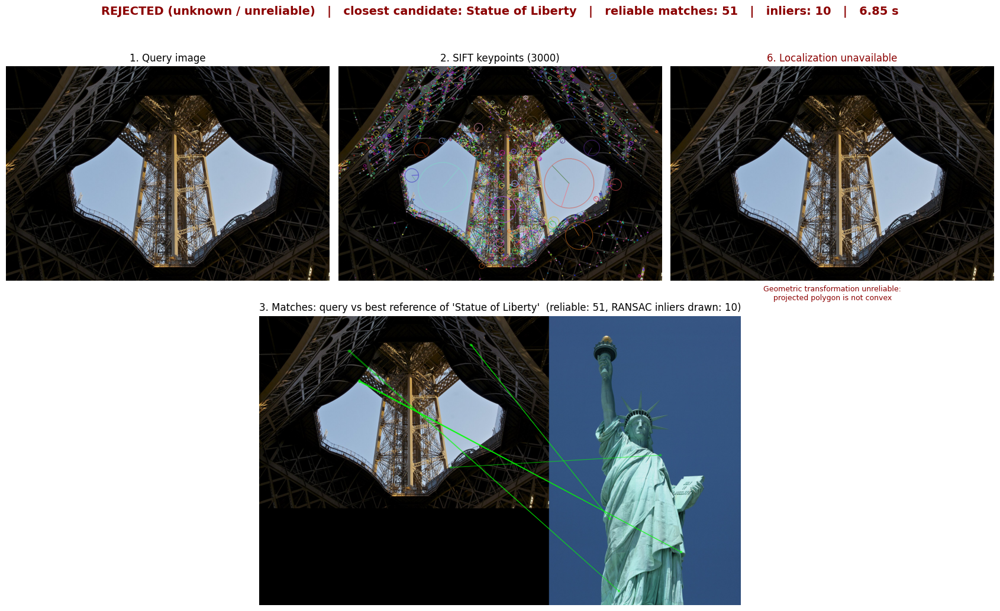

Rejection reason(s): projected polygon is not convex

Predicted landmark: Statue of Liberty  |  reliable matches: 51  |  decision: REJECTED  |  6.85s


In [17]:
import requests
url = "https://commons.wikimedia.org/wiki/Special:FilePath/Tour_Eiffel_pilier_sud_vu_de_dessous.jpg?width=1024"
r = requests.get(url, headers={"User-Agent": "LandmarkSIFTLab/1.0 (student lab)"}, timeout=60)
print(r.status_code, r.headers.get("Content-Type"))   # should say 200 image/jpeg
open("query.jpg", "wb").write(r.content)

q, out, dt = run_pipeline("query.jpg", save_as="query_result.png")
print(f"\nPredicted landmark: {out['label']}  |  reliable matches: {out['n_good']}  |  decision: {'RECOGNIZED' if out['recognized'] else 'REJECTED'}  |  {dt:.2f}s")

In [18]:
BASE_LABEL      = "Eiffel Tower"
BASE_QUERY      = None
VIEWPOINT_QUERY = None
UNKNOWN_QUERY   = None

held = find_images(os.path.join(TEST_DIR, BASE_LABEL))
BASE_QUERY      = BASE_QUERY      or (held[0] if held else None)
VIEWPOINT_QUERY = VIEWPOINT_QUERY or (held[1] if len(held) > 1 else None)
unk = find_images(os.path.join(TEST_DIR, "_unknown"))
UNKNOWN_QUERY   = UNKNOWN_QUERY   or (unk[0] if unk else None)
assert BASE_QUERY, f"Put at least one held-out photo in {TEST_DIR}/{BASE_LABEL}/ or set BASE_QUERY"
assert UNKNOWN_QUERY, f"Put an image of a non-database landmark in {TEST_DIR}/_unknown/ or set UNKNOWN_QUERY"
print("Base:", BASE_QUERY, "| Viewpoint:", VIEWPOINT_QUERY or "(synthetic warp)", "| Unknown:", UNKNOWN_QUERY)

def rotate_image(img, angle):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    c, s = abs(M[0, 0]), abs(M[0, 1])
    nw, nh = int(h * s + w * c), int(h * c + w * s)
    M[0, 2] += nw / 2 - w / 2; M[1, 2] += nh / 2 - h / 2
    return cv2.warpAffine(img, M, (nw, nh), borderValue=(0, 0, 0))

def resize_image(img, scale):
    return cv2.resize(img, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)

def darken_image(img, factor=0.35):
    return cv2.convertScaleAbs(img, alpha=factor, beta=0)

def warp_viewpoint(img, strength=0.18):
    h, w = img.shape[:2]
    src = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
    dst = np.float32([[strength * w, strength * h * 0.6], [w * (1 - strength * 0.2), 0],
                      [w, h], [0, h * (1 - strength * 0.6)]])
    return cv2.warpPerspective(img, cv2.getPerspectiveTransform(src, dst), (w, h))

Base: test_queries/Eiffel Tower/test_01.jpg | Viewpoint: test_queries/Eiffel Tower/test_02.jpg | Unknown: test_queries/_unknown/test_01.jpg


1. Original image   (expected: Eiffel Tower)


,Landmark,Reliable matches (best ref. image),Total reliable matches (all refs),RANSAC inliers,Best reference
Rank,,,,,
1,Statue of Liberty,26,93,6,ref_05.jpg
2,Colosseum,18,69,4,ref_05.jpg
3,Great Wall of China,16,70,5,ref_02.jpg
4,Eiffel Tower,14,66,0,ref_01.jpg
5,Taj Mahal,11,51,0,ref_04.jpg


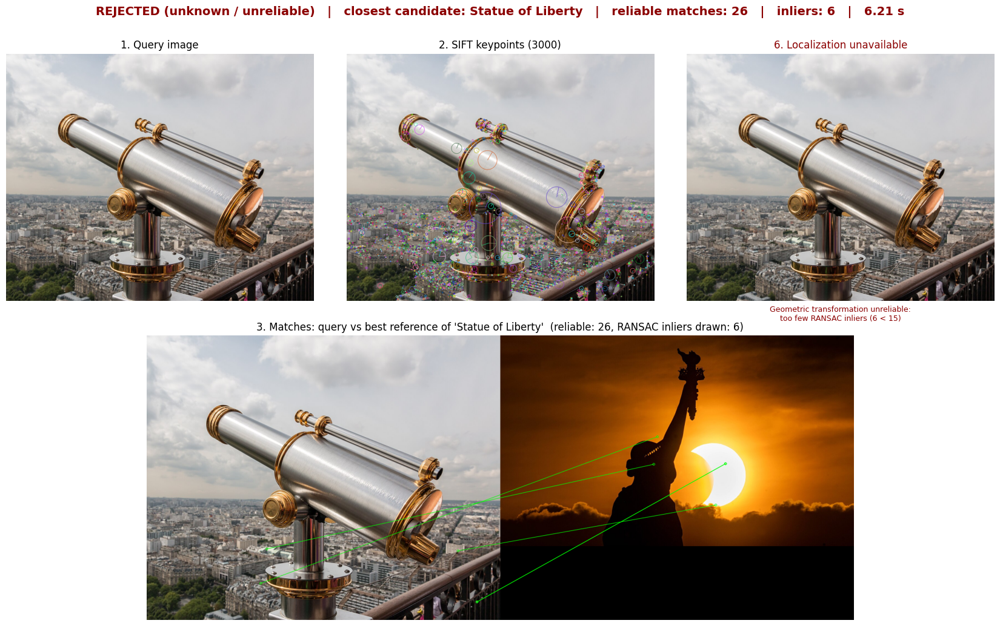

Rejection reason(s): too few RANSAC inliers (6 < 15)
2. Rotated (45 deg)   (expected: Eiffel Tower)


,Landmark,Reliable matches (best ref. image),Total reliable matches (all refs),RANSAC inliers,Best reference
Rank,,,,,
1,Statue of Liberty,28,103,5,ref_05.jpg
2,Eiffel Tower,23,84,6,ref_01.jpg
3,Colosseum,22,86,4,ref_04.jpg
4,Great Wall of China,22,71,7,ref_05.jpg
5,Taj Mahal,14,69,0,ref_01.jpg


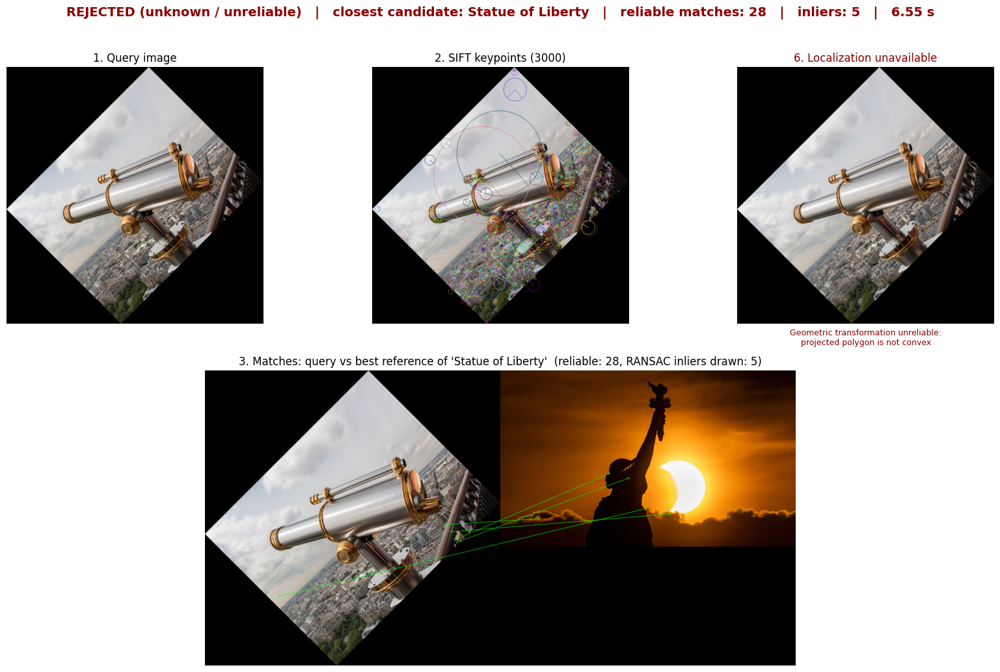

Rejection reason(s): projected polygon is not convex
3. Resized (50 %)   (expected: Eiffel Tower)


,Landmark,Reliable matches (best ref. image),Total reliable matches (all refs),RANSAC inliers,Best reference
Rank,,,,,
1,Statue of Liberty,14,43,0,ref_04.jpg
2,Taj Mahal,12,29,0,ref_04.jpg
3,Colosseum,9,44,0,ref_04.jpg
4,Eiffel Tower,9,31,0,ref_05.jpg
5,Great Wall of China,8,32,0,ref_01.jpg


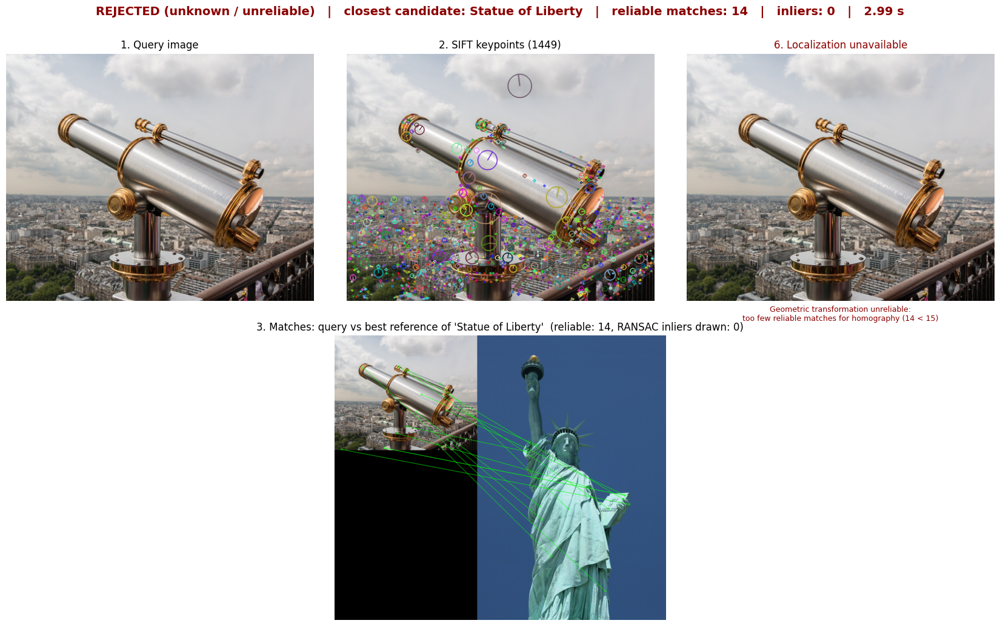

Rejection reason(s): only 14 reliable matches (< 20); too few reliable matches for homography (14 < 15)
4. Reduced brightness (35 %)   (expected: Eiffel Tower)


,Landmark,Reliable matches (best ref. image),Total reliable matches (all refs),RANSAC inliers,Best reference
Rank,,,,,
1,Statue of Liberty,15,46,6,ref_05.jpg
2,Great Wall of China,12,35,0,ref_05.jpg
3,Colosseum,9,22,0,ref_05.jpg
4,Eiffel Tower,7,27,0,ref_03.jpg
5,Taj Mahal,6,25,0,ref_03.jpg


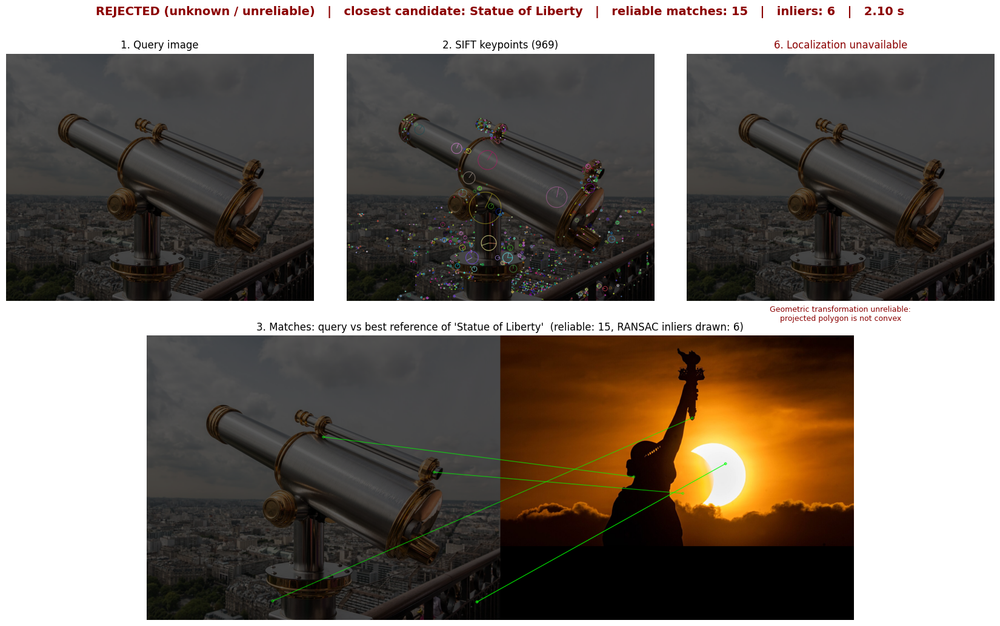

Rejection reason(s): only 15 reliable matches (< 20); projected polygon is not convex
5. Different viewpoint   (expected: Eiffel Tower)


,Landmark,Reliable matches (best ref. image),Total reliable matches (all refs),RANSAC inliers,Best reference
Rank,,,,,
1,Statue of Liberty,44,160,6,ref_04.jpg
2,Colosseum,26,107,9,ref_03.jpg
3,Taj Mahal,26,106,7,ref_02.jpg
4,Great Wall of China,24,86,5,ref_05.jpg
5,Eiffel Tower,21,101,4,ref_06.jpg


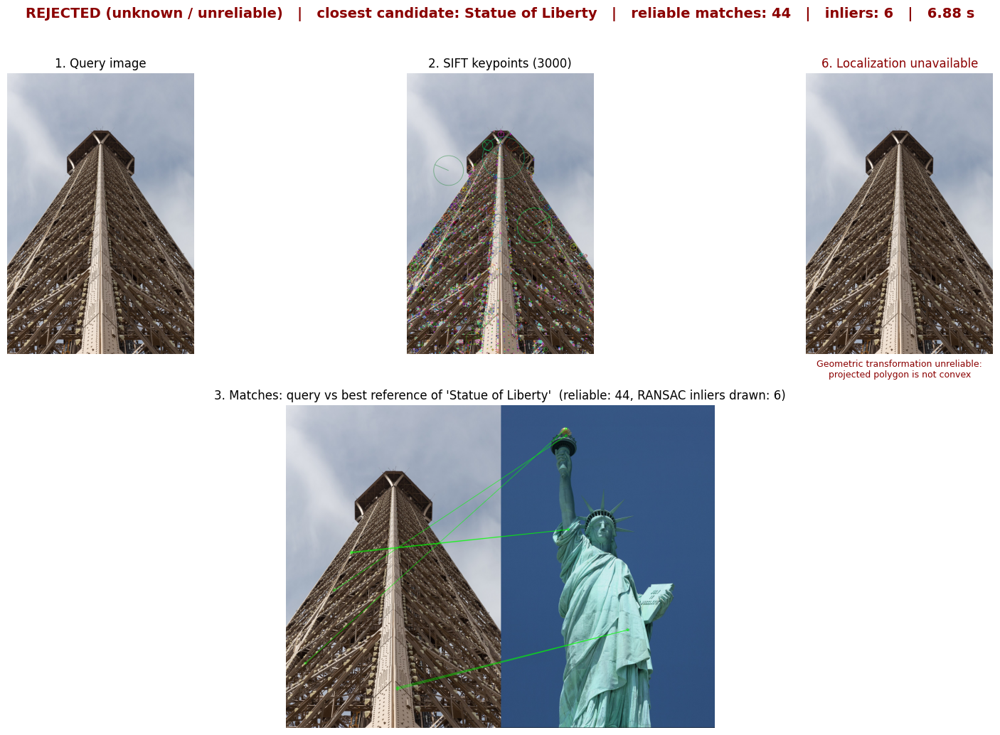

Rejection reason(s): projected polygon is not convex
6. Landmark not in database   (expected: Unknown)


,Landmark,Reliable matches (best ref. image),Total reliable matches (all refs),RANSAC inliers,Best reference
Rank,,,,,
1,Statue of Liberty,12,50,0,ref_05.jpg
2,Eiffel Tower,11,34,0,ref_01.jpg
3,Taj Mahal,9,36,0,ref_02.jpg
4,Great Wall of China,8,30,0,ref_06.jpg
5,Colosseum,7,28,0,ref_02.jpg


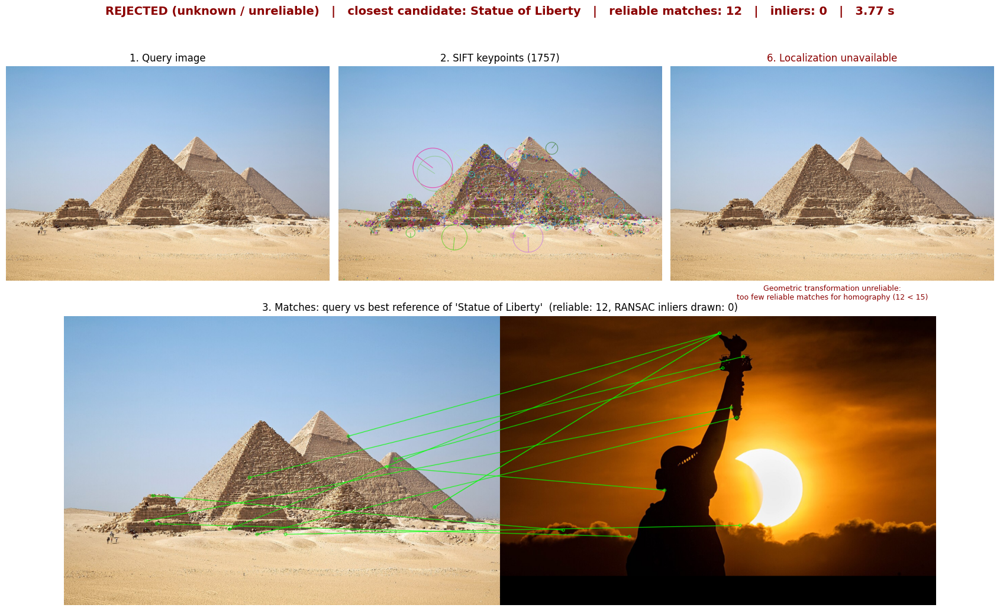

Rejection reason(s): only 12 reliable matches (< 20); too few reliable matches for homography (12 < 15)

EXPERIMENTAL RESULTS


,Expected,Predicted,Closest candidate,Keypoints,Reliable matches,RANSAC inliers,Decision,Correct,Time (s)
Test,,,,,,,,,
1. Original image,Eiffel Tower,None (rejected),Statue of Liberty,3000,26,6,Rejected,No,6.21
2. Rotated (45 deg),Eiffel Tower,None (rejected),Statue of Liberty,3000,28,5,Rejected,No,6.55
3. Resized (50 %),Eiffel Tower,None (rejected),Statue of Liberty,1449,14,0,Rejected,No,2.99
4. Reduced brightness (35 %),Eiffel Tower,None (rejected),Statue of Liberty,969,15,6,Rejected,No,2.10
5. Different viewpoint,Eiffel Tower,None (rejected),Statue of Liberty,3000,44,6,Rejected,No,6.88
6. Landmark not in database,Unknown,None (rejected),Statue of Liberty,1757,12,0,Rejected,Yes,3.77


In [19]:
base_img = load_image(BASE_QUERY)
viewpoint_img = load_image(VIEWPOINT_QUERY) if VIEWPOINT_QUERY else warp_viewpoint(base_img)

test_cases = [
    ("1. Original image",              BASE_LABEL, base_img),
    ("2. Rotated (45 deg)",            BASE_LABEL, rotate_image(base_img, 45)),
    ("3. Resized (50 %)",              BASE_LABEL, resize_image(base_img, 0.5)),
    ("4. Reduced brightness (35 %)",   BASE_LABEL, darken_image(base_img, 0.35)),
    ("5. Different viewpoint" + ("" if VIEWPOINT_QUERY else " (synthetic)"), BASE_LABEL, viewpoint_img),
    ("6. Landmark not in database",    "Unknown",  load_image(UNKNOWN_QUERY)),
]

rows = []
for i, (name, expected, img) in enumerate(test_cases, 1):
    print("=" * 110, f"\n{name}   (expected: {expected})")
    q, out, dt = run_pipeline(img, save_as=f"task6_test{i}.png")
    decision = "Recognized" if out["recognized"] else "Rejected"
    correct = (not out["recognized"]) if expected == "Unknown" else (out["recognized"] and out["label"] == expected)
    rows.append({"Test": name, "Expected": expected,
                 "Predicted": out["label"] if out["recognized"] else "None (rejected)",
                 "Closest candidate": out["label"],
                 "Keypoints": len(q["kp"]), "Reliable matches": out["n_good"], "RANSAC inliers": out["n_inliers"],
                 "Decision": decision, "Correct": "Yes" if correct else "No", "Time (s)": round(dt, 2)})

results = pd.DataFrame(rows).set_index("Test")
results.to_csv(os.path.join(OUT_DIR, "task6_results.csv"))
print("\nEXPERIMENTAL RESULTS")
display(results)

In [20]:
rows = []
for lab in sorted(os.listdir(TEST_DIR)):
    folder = os.path.join(TEST_DIR, lab)
    if not os.path.isdir(folder) or lab.startswith("_tmp"): continue
    expected = "Unknown" if lab == "_unknown" else lab
    for p in find_images(folder):
        q, out, dt = run_pipeline(p, show=False)
        correct = (not out["recognized"]) if expected == "Unknown" else (out["recognized"] and out["label"] == expected)
        rows.append({"Image": f"{lab}/{os.path.basename(p)}", "Expected": expected,
                     "Predicted": out["label"] if out["recognized"] else "None (rejected)",
                     "Keypoints": len(q["kp"]), "Reliable matches": out["n_good"], "RANSAC inliers": out["n_inliers"],
                     "Correct": correct, "Time (s)": round(dt, 2)})
ext = pd.DataFrame(rows)
ext.to_csv(os.path.join(OUT_DIR, "extended_results.csv"), index=False)
display(ext)
print(f"Accuracy on {len(ext)} held-out queries: {ext['Correct'].mean() * 100:.1f}%")

,Image,Expected,Predicted,Keypoints,Reliable matches,RANSAC inliers,Correct,Time (s)
0,Colosseum/test_01.jpg,Colosseum,None (rejected),3001,28,1,False,6.44
1,Colosseum/test_02.jpg,Colosseum,None (rejected),3001,114,8,False,7.32
2,Eiffel Tower/test_01.jpg,Eiffel Tower,None (rejected),3000,26,6,False,6.30
3,Eiffel Tower/test_02.jpg,Eiffel Tower,None (rejected),3000,44,6,False,6.68
4,Great Wall of China/test_01.jpg,Great Wall of China,Great Wall of China,3001,325,170,True,6.18
5,Great Wall of China/test_02.jpg,Great Wall of China,Great Wall of China,3000,77,28,True,6.44
6,Statue of Liberty/test_01.jpg,Statue of Liberty,None (rejected),715,27,7,False,1.82
7,Statue of Liberty/test_02.jpg,Statue of Liberty,None (rejected),3000,36,5,False,6.47
8,Taj Mahal/test_01.jpg,Taj Mahal,Taj Mahal,2260,1539,1511,True,5.36
9,Taj Mahal/test_02.jpg,Taj Mahal,Taj Mahal,2339,1144,1097,True,5.60


Accuracy on 12 held-out queries: 50.0%


In [21]:
shutil.make_archive("lab_outputs", "zip", OUT_DIR)
shutil.make_archive("landmarks_db_archive", "zip", DB_DIR)
try:
    from google.colab import files
    files.download("lab_outputs.zip"); files.download("landmarks_db_archive.zip")
except Exception:
    print("Files saved as lab_outputs.zip and landmarks_db_archive.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Discussion of performance and limitations


**Performance.** SIFT keypoints are invariant to image scale and rotation and robust to moderate illumination change, so the rotated, resized and darkened queries should still gather many reliable matches with the correct landmark. Lowe's ratio test removes ambiguous matches, and RANSAC verification keeps only matches that agree on one geometric transformation, which makes the decision much more reliable than counting matches alone. Requiring a minimum number of inliers, a minimum inlier ratio and a margin over the runner-up landmark lets the system reject an unknown landmark instead of forcing a wrong label.

**Limitations.**
* SIFT is only partially invariant to viewpoint: large perspective changes, oblique views or heavy occlusion reduce the number of matches and may cause rejection.
* Repetitive structures (Colosseum arches, Great Wall bricks, building windows) produce ambiguous descriptors; the ratio test discards many of them, lowering match counts.
* Very dark, blurred or low-resolution images yield few keypoints.
* A single planar homography is only an approximation for 3-D structures such as towers and statues, so the drawn polygon is approximate; it is a bounding quadrilateral of the reference frame, not a tight object outline.
* Brute-force matching against every reference image is O(images x keypoints²); it is acceptable for a small database but would need approximate nearest-neighbor search (FLANN / FAISS) or a vocabulary tree for large ones.
* Landmarks with few or similar reference views (and visually similar structures) can be confused; more diverse reference images per landmark improve recall.
